# Experimento 03 - Análise Temática de Diálogos

In [43]:
#pip install -r requirements.txt2

In [44]:
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from sklearn.metrics.pairwise import cosine_similarity

In [45]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir uma conversa entre duas personas. Considere que a conversa pode ser natural (pode ser como num formato de podcast). Seu trabalho e gerar uma conversa extensa que começa com tópicos relacionados à {topic_1}, mas que gradualmente se move para tópicos relacionados a {topic_2}.

Siga o seguinte padrão para a conversa:

Persona 1: [fala algo que pode ser relacionado a {topic_1}]
Persona 2: [responde, ainda relacionado a {topic_1} ou fazendo uma transição suave]
... 


---------------

Continue a conversa por pelo menos 100 trocas de mensagens
"""

prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [46]:
response = chain.invoke({
    "topic_1": "história",
    "topic_2": "matemática"
})

In [47]:
def select_persona(message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversation_list = response.split("\n")
conversation_list = [line for line in conversation_list if line.strip() != ""]
conversation_list_persona = [{"persona": select_persona(line), "message": line[11:]} for line in conversation_list]

In [48]:
system_prompt_summary = """
Você é um assistente inteligente que vai resumir uma conversa entre duas personas. Você vai receber uma lista de mensagens, cada uma associada a uma persona (Persona 1 ou Persona 2). Seu trabalho é gerar um resumo conciso da conversa, dê enfase para o tópico principal discutido na conversa no momento atual (mesmo que o tópico tenha mudado ao longo da conversa). Os tópicos devem girar em torno de {topic_1} e {topic_2}.
"""

prompt_summary = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt_summary),
            ("human", "Resuma a conversa dada: {conversation}"),
        ]
)

chain_summary = prompt_summary | llm | StrOutputParser()

In [49]:
summary_list = []
buffer = []
for i in tqdm(range(len(conversation_list))):
    buffer.append(conversation_list[i])
    buffer_trimmed = buffer[-10:]  
    buffer_str = "\n".join(buffer_trimmed)
    response_summary = chain_summary.invoke({
        "topic_1": "história",
        "topic_2": "matematica",
        "conversation": buffer_str
    })
    summary_list.append(response_summary)

100%|██████████| 34/34 [01:06<00:00,  1.96s/it]


In [50]:
all_data_list = []
for i in range(len(conversation_list)):
    all_data_list.append({
        "summary": summary_list[i],
        "persona": conversation_list_persona[i]["persona"],
        "message": conversation_list_persona[i]["message"]
    })

os.makedirs("../data/conversation", exist_ok=True)

with open("../data/conversation/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

with open("../data/conversation/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'summary': 'Persona 1 comentou sobre o Império Romano, destacando sua capacidade de manter uma civilização vasta e organizada por tanto tempo, mesmo sem as tecnologias modernas.', 'persona': 'Unknown', 'message': ':** Sabe, estava lendo sobre o Império Romano esses dias. É impressionante como eles conseguiram manter uma civilização tão organizada e espalhada por tanto tempo. Quero dizer, não tinham a tecnologia que temos hoje, mas ainda assim criaram uma infraestrutura incrível.'}, {'summary': 'A conversa destaca a admiração pelo Império Romano, com foco na organização e infraestrutura avançada, em especial as estradas romanas, que exemplificam a inteligência logística e a durabilidade de suas construções.', 'persona': 'Unknown', 'message': ':** Totalmente! As estradas romanas ainda me fascinam. Foram projetadas de forma tão inteligente que muitas delas ainda existem hoje. A logística daquele tempo era realmente impressionante, mantendo comunicações e tropas se movimentando tão rapid

In [51]:
file_path_matematica = "pdfs2/MatematicaI.pdf"
file_path_historia   = "pdfs2/HistoriaI.pdf"

loader_historia   = PyPDFLoader(file_path_historia)
loader_matematica = PyPDFLoader(file_path_matematica)

pages_historia   = loader_historia.load()
pages_matematica = loader_matematica.load()

n_pages = 30
selected_historia   = pages_historia[:n_pages]
selected_matematica = pages_matematica[:n_pages]


In [52]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)


In [53]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=5000,
    chunk_overlap=1500,
    length_function=len,
    is_separator_regex=False,
)

chunks_historia = text_splitter.split_documents(selected_historia)
chunks_matematica = text_splitter.split_documents(selected_matematica)
len(chunks_historia), len(chunks_matematica)

(58, 32)

In [54]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
len(chunks_conversation)

34

In [55]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))
vectors_matematica = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_matematica]))
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_matematica], axis=0)
vectors_conversation.shape, vectors_matematica.shape, vectors_historia.shape, all_vectors.shape

((34, 1536), (32, 1536), (58, 1536), (124, 1536))

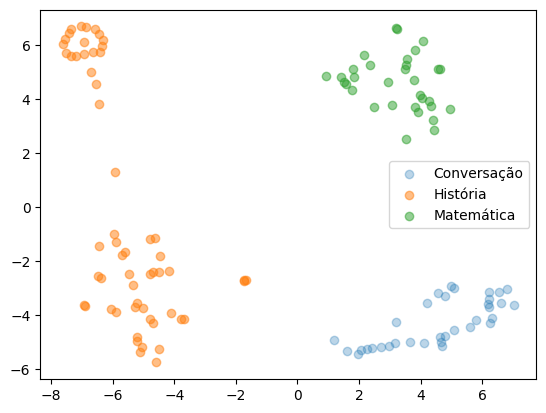

In [56]:
tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="História", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Matemática", alpha=0.5)
plt.legend()
plt.show()

In [57]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_matematica = np.mean(vectors_matematica, axis=0)

In [58]:
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_matematica = cosine_similarity(vectors_conversation, centroid_matematica.reshape(1, -1))
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_matematica": similarity_to_matematica[i, 0]
    })
df = pd.DataFrame(content_and_similarities)
df.sort_values(by="similarity_to_matematica", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
27,A conversa gira em torno da importância da mat...,0.340318,0.506049
29,A conversa entre as personas aborda o papel fu...,0.296275,0.493874
17,A conversa gira em torno da relação entre mate...,0.373208,0.493439
30,A conversa gira em torno do papel fundamental ...,0.288694,0.489176
24,A conversa gira em torno da intersecção entre ...,0.298219,0.489049
23,A conversa gira em torno da interconexão entre...,0.348450,0.487360
32,A conversa explora a relação entre matemática ...,0.280478,0.487319
26,A conversa gira em torno da importância da mat...,0.305569,0.485093
22,A conversa teve como foco principal a relação ...,0.329148,0.475965
25,A conversa girou em torno do impacto transform...,0.360149,0.475535


In [59]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
7,A conversa gira em torno das conquistas do Imp...,0.461628,0.428364
8,A conversa girou em torno das conquistas do Im...,0.460543,0.400431
9,A conversa gira em torno das conquistas histór...,0.459114,0.408186
2,A conversa gira em torno das realizações do Im...,0.454580,0.330867
4,A conversa gira em torno do legado do Império ...,0.452645,0.342459
5,A conversa gira em torno das realizações do Im...,0.451947,0.387315
3,A conversa girou em torno das conquistas do Im...,0.450874,0.341421
6,A conversa gira em torno das impressionantes c...,0.449369,0.399076
10,A conversa gira em torno das contribuições mat...,0.447128,0.435292
1,A conversa destaca a admiração pelo Império Ro...,0.414820,0.297624


In [60]:
example_matematica = df.sort_values(by="similarity_to_matematica", ascending=False).head(10)['chunk'].values
for x in example_matematica:
    print(x)

A conversa gira em torno da importância da matemática como linguagem universal para descrever o mundo físico e avançar o conhecimento humano. Persona 1 e Persona 2 discutem como as equações de Maxwell conectam a matemática ao mundo real, possibilitando avanços como rádio, Wi-Fi e aparelhos celulares. Eles destacam aplicações matemáticas, desde vetores e integrais em engenharia, álgebra linear e estatística em inteligência artificial, até redes neurais que simulam o cérebro humano. A discussão evolui para o impacto das transformadas de Fourier na tecnologia moderna e como conceitos básicos, como operações elementares, sustentam áreas complexas como a física quântica. Ambos expressam admiração pela capacidade da matemática de explicar desde sistemas macroscópicos até fenômenos subatômicos que desafiam a intuição.
A conversa entre as personas aborda o papel fundamental da matemática como base para avanços científicos e tecnológicos. Elas discutem como conceitos matemáticos, desde os mais 

In [61]:
example_historia = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_historia:
    print(x)

A conversa gira em torno das conquistas do Império Romano e sua relação com a matemática. Persona 1 e Persona 2 destacam a engenharia romana, como aquedutos e estradas, e como a aplicação prática da geometria e álgebra na época foi essencial para esses avanços. Eles discutem a herança do conhecimento matemático das civilizações antigas, como gregos, romanos e árabes, e comentam a evolução dos sistemas numéricos, especialmente a transição dos numerais romanos para o sistema decimal, que revolucionou cálculos e avanços científicos. Ao final, mencionam o sistema sexagesimal babilônico, admirando a diversidade de abordagens matemáticas na história.
A conversa girou em torno das conquistas do Império Romano em engenharia e matemática, destacando sua habilidade em construir infraestrutura complexa como aquedutos e estradas, mesmo com tecnologias limitadas. Os participantes discutiram como os romanos aplicaram conhecimentos matemáticos, como geometria e álgebra, de forma prática, e refletiram